# 1. Data Exploration — SPAGHETTI-1 Stellar Classification (`an2dl2627`)

**Objective:** Perform a thorough exploratory data analysis (EDA) of the `256 × 256` RGB stellar image dataset captured by SPAGHETTI-1 (`artifacts/dataset/`), focusing on:
1. Dataset integrity, split sizes, and label distribution (evaluation metric: **weighted F1-score**).
2. Visual inspection of representative samples across all 10 classes (`0..9`).
3. Full-dataset image quality & anomaly scan (blank/empty frames, extreme noise, color distortions, clipped pixels).
4. Exact and perceptual duplicate / near-duplicate detection (within-train, within-test, and train ↔ test overlap).
5. Systematic spatial & frequency-domain disturbances (pixel mean/std maps and 2D FFT spectrum).
6. Train vs. test distribution shift comparison.

In [1]:
import hashlib
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

# Resolve repository root reliably whether executed from repo root or notebooks/
def find_repo_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate pyproject.toml in current or parent directories.")

REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from data.visualization import (
    plot_class_distribution,
    plot_class_samples,
    plot_distribution_comparison,
    plot_duplicate_pairs,
    plot_image_grid,
    plot_spatial_maps,
)

# Reproducibility & paths
SEED = 42
rng = np.random.default_rng(SEED)

DATASET_DIR = REPO_ROOT / "artifacts" / "dataset"
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Plotting defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.facecolor"] = "white"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print(f"Repository root: {REPO_ROOT}")
print(f"Dataset dir:     {DATASET_DIR}")

mkdir -p failed for path /home/carruc/.config/matplotlib: [Errno 30] Read-only file system: '/home/carruc/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-l5kchx1_ because there was an issue with the default path (/home/carruc/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Repository root: /home/carruc/repos/reward-lacking
Dataset dir:     /home/carruc/repos/reward-lacking/artifacts/dataset


## 2. Dataset Overview & Integrity Checks

Verify CSV schemas, missing values, duplicate IDs, label range, and 1-to-1 correspondence between CSV IDs and `.png` files on disk.

In [2]:
train_df = pd.read_csv(DATASET_DIR / "train.csv")
test_df = pd.read_csv(DATASET_DIR / "sample_submission.csv")

print("Train CSV shape:", train_df.shape)
print("Test CSV shape: ", test_df.shape)
print(f"Test-to-train ratio: {len(test_df) / len(train_df):.2f}x\n")

print("Train dtypes & nulls:")
print(train_df.dtypes)
print(train_df.isna().sum())
print("\nTest nulls:")
print(test_df.isna().sum())

print("\nUnique train IDs:", train_df["id"].nunique(), "| Exact ID duplicates:", train_df["id"].duplicated().sum())
print("Unique test IDs: ", test_df["id"].nunique(), "| Exact ID duplicates:", test_df["id"].duplicated().sum())
print("Sorted train labels:", sorted(train_df["label"].unique().tolist()))

# Cross-check files on disk vs CSV IDs
train_disk_ids = {p.stem for p in TRAIN_DIR.glob("*.png")}
test_disk_ids = {p.stem for p in TEST_DIR.glob("*.png")}

train_csv_ids = set(train_df["id"])
test_csv_ids = set(test_df["id"])

print("\nFile correspondence:")
print("  Train missing on disk:", len(train_csv_ids - train_disk_ids), "| Extra on disk:", len(train_disk_ids - train_csv_ids))
print("  Test missing on disk: ", len(test_csv_ids - test_disk_ids), "| Extra on disk:", len(test_disk_ids - test_csv_ids))
print("  Non-PNG files in train:", [p.name for p in TRAIN_DIR.iterdir() if p.suffix != ".png"])
print("  Non-PNG files in test: ", [p.name for p in TEST_DIR.iterdir() if p.suffix != ".png"])

display(train_df.head())
display(test_df.head())

Train CSV shape: (4328, 2)
Test CSV shape:  (14736, 2)
Test-to-train ratio: 3.40x

Train dtypes & nulls:
id         str
label    int64
dtype: object
id       0
label    0
dtype: int64

Test nulls:
id       0
label    0
dtype: int64

Unique train IDs: 4328 | Exact ID duplicates: 0
Unique test IDs:  14736 | Exact ID duplicates: 0
Sorted train labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

File correspondence:
  Train missing on disk: 0 | Extra on disk: 0
  Test missing on disk:  0 | Extra on disk: 0
  Non-PNG files in train: []
  Non-PNG files in test:  []


,id,label
0,train_00000,3
1,train_00001,2
2,train_00002,9
3,train_00003,1
4,train_00004,9


,id,label
0,test_00000,0
1,test_00001,0
2,test_00002,0
3,test_00003,0
4,test_00004,0


## 3. Class Distribution & Imbalance

The leaderboard metric is **weighted F1-score**:
$$\text{F1}_{\text{weighted}} = \sum_{c=0}^{9} \frac{n_c}{N} \text{F1}_c$$
Because each class is weighted by its test prevalence, understanding class imbalance in `train.csv` helps guide stratified cross-validation, class weighting / focal loss, and augmentation.

,count,share_pct
label,,
0,213,4.92
1,345,7.97
2,744,17.19
3,685,15.83
4,83,1.92
5,584,13.49
6,565,13.05
7,477,11.02
8,276,6.38


Majority class: 2 (744 samples) | Minority class: 4 (83 samples) | Max/Min ratio: 8.96x


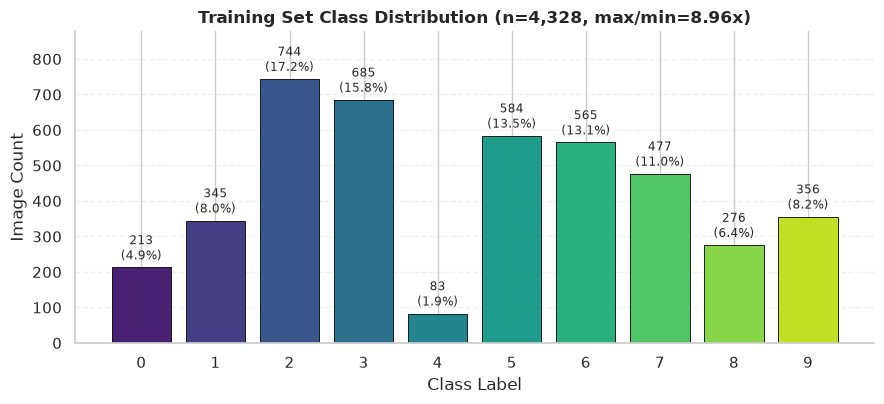

In [3]:
class_counts = train_df["label"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "count": class_counts,
    "share_pct": (class_counts / len(train_df) * 100.0).round(2),
})
class_summary.index.name = "label"
display(class_summary)

imbalance_ratio = class_counts.max() / class_counts.min()
print(
    f"Majority class: {class_counts.idxmax()} ({class_counts.max()} samples) | "
    f"Minority class: {class_counts.idxmin()} ({class_counts.min()} samples) | "
    f"Max/Min ratio: {imbalance_ratio:.2f}x"
)

ax = plot_class_distribution(train_df["label"], title="Training Set Class Distribution")
plt.tight_layout()
plt.show()

## 4. Representative Samples per Class

Inspect random samples from each of the 10 classes (`0..9`) to build intuition about stellar morphology, backgrounds, and visible artifacts.

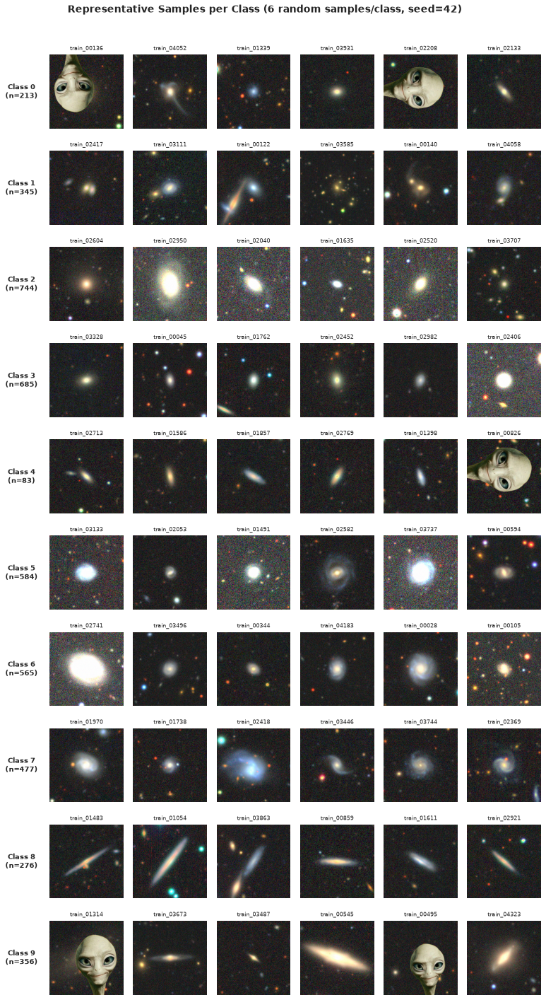

In [4]:
fig = plot_class_samples(train_df, TRAIN_DIR, samples_per_class=6, seed=SEED)
plt.show()

## 5. Full-Dataset Image Statistics & Quality Scan (Train & Test)

Decode every image in both `train/` (4,328 images) and `test/` (14,736 images) to extract:
- **File & format metadata:** dimensions, color mode, PNG file size, readability check.
- **Intensity & color statistics:** per-channel RGB mean/std, grayscale brightness/contrast, channel differences (`R-G`, `R-B`, `G-B`), `color_spread`, mean HSV saturation (`mean_sat`), and clipped pixel fractions (`== 0` and `== 255`).
- **Spatial & high-frequency metrics:** center `64 × 64` vs. outer border (`24 px` margin) intensity difference/ratio, plus gradient / Laplacian energy (`sharpness`).
- **Duplicate fingerprints:** `file_md5`, raw RGB `pixel_md5`, and 64-bit `dHash`.
- **Dataset-wide spatial maps:** per-pixel mean, per-pixel std, and average log 2D FFT magnitude spectrum.

In [5]:
# Precompute spatial masks for 256x256 images
IMG_H, IMG_W = 256, 256
CENTER_SLICE = (slice(96, 160), slice(96, 160))  # 64x64 center window
BORDER_MASK = np.ones((IMG_H, IMG_W), dtype=bool)
BORDER_MASK[24:232, 24:232] = False  # outer 24px border


def _compute_dhash_bits(img: Image.Image) -> np.ndarray:
    """Compute a 64-bit difference hash (dHash) bit vector from an image."""
    small = np.asarray(img.convert("L").resize((9, 8), Image.Resampling.BILINEAR), dtype=np.uint8)
    return (small[:, 1:] > small[:, :-1]).ravel()


def _extract_single_image(args: tuple[str, Path]) -> tuple[dict, np.ndarray, np.ndarray | None]:
    """Extract quality/color/spatial statistics and raw RGB array for one image."""
    img_id, path = args
    file_bytes = path.read_bytes()
    file_size = len(file_bytes)
    file_md5 = hashlib.md5(file_bytes).hexdigest()

    try:
        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode
            rgb_img = img.convert("RGB")
            arr = np.asarray(rgb_img, dtype=np.uint8)
            dhash_bits = _compute_dhash_bits(rgb_img)
        corrupt = False
    except Exception:
        empty_meta = {
            "id": img_id,
            "width": np.nan,
            "height": np.nan,
            "mode": "CORRUPT",
            "file_size": file_size,
            "corrupt": True,
            "file_md5": file_md5,
            "pixel_md5": "",
            "dhash_hex": "",
        }
        return empty_meta, np.zeros(64, dtype=np.uint8), None

    arr_f = arr.astype(np.float32)
    pixel_md5 = hashlib.md5(arr.tobytes()).hexdigest()
    dhash_int = int(np.packbits(dhash_bits).tobytes().hex(), 16)

    mean_rgb = arr_f.mean(axis=(0, 1))
    std_rgb = arr_f.std(axis=(0, 1))

    # Luminance grayscale and saturation
    gray = 0.299 * arr_f[:, :, 0] + 0.587 * arr_f[:, :, 1] + 0.114 * arr_f[:, :, 2]
    max_c = arr_f.max(axis=2)
    min_c = arr_f.min(axis=2)
    sat = np.where(max_c > 0.0, (max_c - min_c) / np.maximum(max_c, 1.0), 0.0)

    # Spatial center vs border
    center_patch = gray[CENTER_SLICE]
    border_vals = gray[BORDER_MASK]
    center_mean = float(center_patch.mean())
    border_mean = float(border_vals.mean())

    # High-frequency energy via discrete Laplacian
    lap = (
        -4.0 * gray[1:-1, 1:-1]
        + gray[:-2, 1:-1]
        + gray[2:, 1:-1]
        + gray[1:-1, :-2]
        + gray[1:-1, 2:]
    )

    meta = {
        "id": img_id,
        "width": width,
        "height": height,
        "mode": mode,
        "file_size": file_size,
        "corrupt": corrupt,
        "mean_r": float(mean_rgb[0]),
        "mean_g": float(mean_rgb[1]),
        "mean_b": float(mean_rgb[2]),
        "std_r": float(std_rgb[0]),
        "std_g": float(std_rgb[1]),
        "std_b": float(std_rgb[2]),
        "mean_gray": float(gray.mean()),
        "std_gray": float(gray.std()),
        "min_val": int(arr.min()),
        "max_val": int(arr.max()),
        "r_minus_g": float(mean_rgb[0] - mean_rgb[1]),
        "r_minus_b": float(mean_rgb[0] - mean_rgb[2]),
        "g_minus_b": float(mean_rgb[1] - mean_rgb[2]),
        "color_spread": float(mean_rgb.max() - mean_rgb.min()),
        "mean_sat": float(sat.mean()),
        "frac_zero": float((arr == 0).all(axis=2).mean()),
        "frac_255": float((arr == 255).any(axis=2).mean()),
        "center_mean": center_mean,
        "center_std": float(center_patch.std()),
        "border_mean": border_mean,
        "border_std": float(border_vals.std()),
        "center_border_diff": center_mean - border_mean,
        "center_border_ratio": center_mean / (border_mean + 1.0),
        "sharpness": float(np.abs(lap).mean()),
        "laplacian_std": float(lap.std()),
        "file_md5": file_md5,
        "pixel_md5": pixel_md5,
        "dhash_hex": f"{dhash_int:016x}",
    }
    return meta, dhash_bits.astype(np.uint8), arr


def scan_split(ids: pd.Series, img_dir: Path, batch_size: int = 512, max_workers: int = 8) -> dict:
    """Scan all images in a split and return metadata DataFrame, dHashes, and spatial maps."""
    tasks = [(str(img_id), img_dir / f"{img_id}.png") for img_id in ids]
    records = []
    dhash_list = []

    sum_img = np.zeros((IMG_H, IMG_W, 3), dtype=np.float64)
    sum_sq_img = np.zeros((IMG_H, IMG_W, 3), dtype=np.float64)
    fft_sum = np.zeros((IMG_H, IMG_W), dtype=np.float64)
    valid_count = 0

    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for start in range(0, len(tasks), batch_size):
            batch_tasks = tasks[start : start + batch_size]
            results = list(pool.map(_extract_single_image, batch_tasks))

            batch_arrs = []
            for meta, bits, arr in results:
                records.append(meta)
                dhash_list.append(bits)
                if arr is not None:
                    batch_arrs.append(arr)

            if batch_arrs:
                stack = np.stack(batch_arrs, axis=0)
                stack_f = stack.astype(np.float64)
                sum_img += stack_f.sum(axis=0)
                sum_sq_img += np.square(stack_f).sum(axis=0)

                gray_batch = (
                    0.299 * stack_f[:, :, :, 0]
                    + 0.587 * stack_f[:, :, :, 1]
                    + 0.114 * stack_f[:, :, :, 2]
                )
                fft_batch = np.fft.fftshift(np.fft.fft2(gray_batch, axes=(-2, -1)), axes=(-2, -1))
                fft_sum += np.log1p(np.abs(fft_batch)).sum(axis=0)
                valid_count += len(batch_arrs)

    df_stats = pd.DataFrame(records)
    dhash_matrix = np.vstack(dhash_list)
    mean_img = sum_img / max(1, valid_count)
    var_img = np.maximum(0.0, sum_sq_img / max(1, valid_count) - np.square(mean_img))
    std_img = np.sqrt(var_img)
    fft_mean = fft_sum / max(1, valid_count)

    return {
        "df": df_stats,
        "dhash": dhash_matrix,
        "mean_img": mean_img,
        "std_img": std_img,
        "fft_mag": fft_mean,
    }


print("Scanning training images...")
train_scan = scan_split(train_df["id"], TRAIN_DIR)
train_stats = train_df.merge(train_scan["df"], on="id", how="left")
train_stats["split"] = "train"
print(f"Done train: {len(train_stats):,} images | corrupt={int(train_stats['corrupt'].sum())}")

print("Scanning test images...")
test_scan = scan_split(test_df["id"], TEST_DIR)
test_stats = test_df[["id"]].merge(test_scan["df"], on="id", how="left")
test_stats["split"] = "test"
print(f"Done test:  {len(test_stats):,} images | corrupt={int(test_stats['corrupt'].sum())}")

Scanning training images...


Done train: 4,328 images | corrupt=0
Scanning test images...


Done test:  14,736 images | corrupt=0


In [6]:
print("Train dimensions:", train_stats[["width", "height"]].value_counts().to_dict(), "| modes:", train_stats["mode"].value_counts().to_dict())
print("Test dimensions: ", test_stats[["width", "height"]].value_counts().to_dict(), "| modes:", test_stats["mode"].value_counts().to_dict())

stat_cols = [
    "file_size",
    "mean_gray",
    "std_gray",
    "min_val",
    "max_val",
    "color_spread",
    "mean_sat",
    "frac_zero",
    "frac_255",
    "center_border_diff",
    "sharpness",
]
print("\n--- Train Numeric Summary ---")
display(train_stats[stat_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T.round(3))
print("\n--- Test Numeric Summary ---")
display(test_stats[stat_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T.round(3))

Train dimensions: {(256, 256): 4328} | modes: {'RGB': 4328}
Test dimensions:  {(256, 256): 14736} | modes: {'RGB': 14736}

--- Train Numeric Summary ---


,count,mean,std,min,1%,5%,50%,95%,99%,max
file_size,4328.0,151097.965,12691.742,103426.000,132050.860,135277.350,149366.000,177549.950,183222.760,191451.000
mean_gray,4328.0,53.846,20.977,31.995,34.402,35.738,43.213,95.092,116.267,180.716
std_gray,4328.0,33.666,12.375,2.010,16.614,19.538,29.967,59.322,65.541,78.852
min_val,4328.0,0.007,0.304,0.000,0.000,0.000,0.000,0.000,0.000,19.000
max_val,4328.0,254.722,4.111,46.000,247.000,255.000,255.000,255.000,255.000,255.000
color_spread,4328.0,4.149,3.073,0.023,0.319,0.715,3.313,10.650,13.140,21.006
mean_sat,4328.0,0.441,0.059,0.142,0.286,0.327,0.447,0.527,0.557,0.616
frac_zero,4328.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
frac_255,4328.0,0.010,0.022,0.000,0.000,0.000,0.002,0.047,0.102,0.391
center_border_diff,4328.0,81.447,39.651,-3.827,10.953,27.068,73.800,157.575,174.352,185.253



--- Test Numeric Summary ---


,count,mean,std,min,1%,5%,50%,95%,99%,max
file_size,14736.0,138111.210,12741.765,103399.000,108066.050,112213.750,138098.500,158100.500,165021.350,179605.000
mean_gray,14736.0,41.116,9.250,12.194,21.125,27.423,39.452,58.466,70.887,197.293
std_gray,14736.0,26.599,7.660,2.013,13.404,16.528,25.186,41.481,49.815,72.475
min_val,14736.0,0.428,1.797,0.000,0.000,0.000,0.000,4.000,10.000,29.000
max_val,14736.0,249.451,14.875,46.000,190.000,210.000,255.000,255.000,255.000,255.000
color_spread,14736.0,3.243,2.654,0.009,0.277,0.608,2.715,7.621,11.405,122.366
mean_sat,14736.0,0.422,0.090,0.139,0.219,0.267,0.425,0.569,0.625,0.743
frac_zero,14736.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.009
frac_255,14736.0,0.002,0.004,0.000,0.000,0.000,0.001,0.008,0.015,0.294
center_border_diff,14736.0,66.587,32.478,-18.591,9.804,22.825,60.977,128.400,156.704,205.655


## 6. Anomaly, Artifact & Corruption Hunt

Investigate potential corrupted or distorted telescope observations across multiple axes:
1. **Blank / empty / ultra-low-contrast frames** (`std_gray`, `file_size`, `center_border_diff`).
2. **Extreme noise / high-energy frames** (`sharpness`, `std_gray`, `file_size`).
3. **Color distortions** (channel imbalances, `color_spread`, `mean_sat`, pixel clipping).
4. **Exact & perceptual duplicates** (`file_md5`, `pixel_md5`, and `dHash` Hamming distance ≤ 4) within and across splits.
5. **Systematic spatial & frequency disturbances** (mean image, per-pixel std, constant pixels, and 2D FFT spectrum).
6. **Multi-feature robust outlier gallery** ("Area 51" anomalies) and per-class anomaly breakdown.

Lowest std_gray in Train:


,id,label,file_size,mean_gray,std_gray,min_val,max_val,center_border_diff,sharpness
3848,train_03848,8,103426,31.994905,2.009894,19,46,-0.004833,7.178366
4294,train_04294,4,136287,33.382317,10.883098,0,255,9.911255,21.380457
1889,train_01889,2,137274,32.546581,11.033561,0,255,5.944370,21.982239
749,train_00749,3,134452,33.492268,12.170445,0,255,14.076820,20.127340
2071,train_02071,0,137699,33.651016,12.230082,0,255,21.308239,22.887609
2722,train_02722,2,133444,33.105083,12.292744,0,255,13.710205,18.670305
1013,train_01013,2,135578,33.786575,12.518915,0,255,5.455853,20.437965
3591,train_03591,2,141266,33.019096,12.532294,0,255,10.034534,26.929415
2264,train_02264,8,130889,33.428082,13.193867,0,255,18.105774,17.116373
3503,train_03503,8,134757,33.779205,13.205329,0,255,18.290314,20.714304


Lowest std_gray in Test:


,id,file_size,mean_gray,std_gray,min_val,max_val,center_border_diff,sharpness
13385,test_13385,103403,31.990711,2.012692,18,46,-0.019321,7.188382
13646,test_13646,103399,32.004684,2.014849,19,46,0.007029,7.166852
11248,test_11248,124009,18.176626,8.106767,0,203,6.496311,14.662358
10874,test_10874,127106,32.187263,8.404990,2,177,6.637415,17.154696
1997,test_01997,108202,32.910896,8.858350,6,226,9.319263,7.523527
6742,test_06742,119882,32.368759,8.885213,0,245,6.358566,11.750296
1705,test_01705,122599,32.828094,9.274575,0,250,4.622250,12.599737
1407,test_01407,124010,24.017609,9.334999,0,147,17.418724,14.019058
5873,test_05873,130858,32.414993,9.431993,0,255,7.856932,17.049955
13970,test_13970,136812,31.709148,9.432758,0,255,3.906656,22.397593


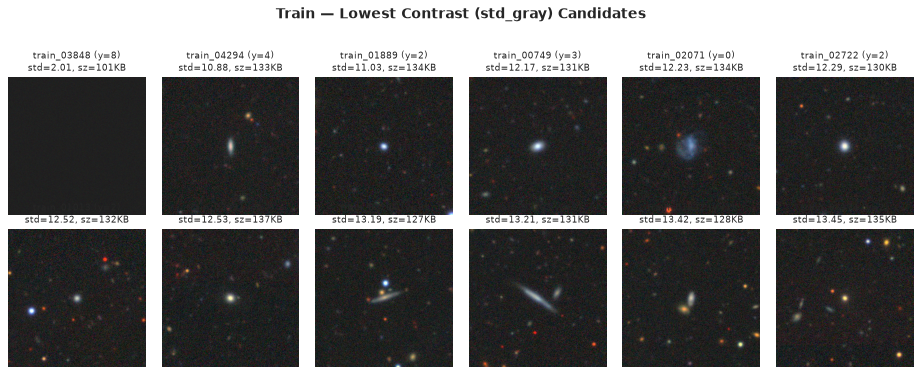

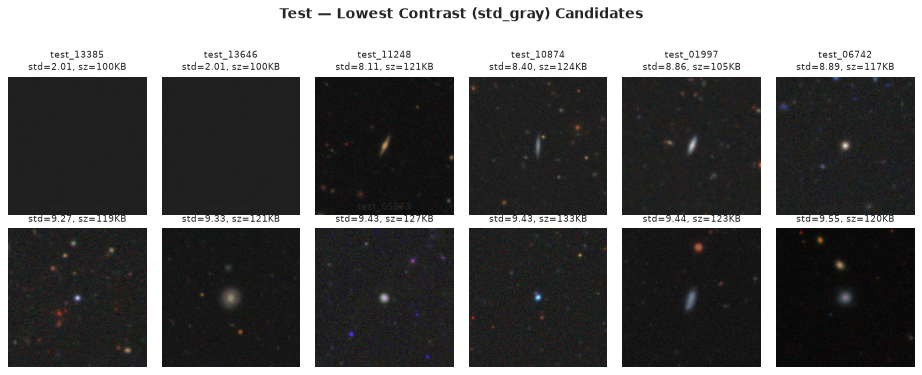

In [7]:
# 6.1 Blank / Low-contrast / Empty Frame Candidates
low_train = train_stats.nsmallest(12, "std_gray")
low_test = test_stats.nsmallest(12, "std_gray")

print("Lowest std_gray in Train:")
display(low_train[["id", "label", "file_size", "mean_gray", "std_gray", "min_val", "max_val", "center_border_diff", "sharpness"]])

print("Lowest std_gray in Test:")
display(low_test[["id", "file_size", "mean_gray", "std_gray", "min_val", "max_val", "center_border_diff", "sharpness"]])

fig = plot_image_grid(
    [TRAIN_DIR / f"{i}.png" for i in low_train["id"]],
    titles=[f"{r.id} (y={r.label})\nstd={r.std_gray:.2f}, sz={r.file_size//1024}KB" for r in low_train.itertuples()],
    ncols=6,
    suptitle="Train — Lowest Contrast (std_gray) Candidates",
)
plt.show()

fig = plot_image_grid(
    [TEST_DIR / f"{i}.png" for i in low_test["id"]],
    titles=[f"{r.id}\nstd={r.std_gray:.2f}, sz={r.file_size//1024}KB" for r in low_test.itertuples()],
    ncols=6,
    suptitle="Test — Lowest Contrast (std_gray) Candidates",
)
plt.show()

Highest sharpness (Laplacian energy) in Train:


,id,label,file_size,mean_gray,std_gray,sharpness,frac_zero,frac_255
1497,train_01497,3,191451,92.578506,50.266663,126.014404,0.000107,0.033005
165,train_00165,3,191451,92.429871,50.231190,125.859009,0.000046,0.033630
3048,train_03048,3,188638,97.609215,53.398087,110.298141,0.000031,0.041672
1322,train_01322,2,188283,84.178474,42.159920,107.544395,0.000061,0.018173
2346,train_02346,3,188294,85.217239,39.975105,103.707390,0.000046,0.009552
2821,train_02821,2,187550,80.118942,45.745094,102.072403,0.000031,0.021011
3963,train_03963,2,186533,90.854462,43.392628,99.468056,0.000000,0.020844
2558,train_02558,6,185943,91.882034,46.427498,98.149483,0.000000,0.030258
3713,train_03713,6,185305,92.450974,53.165131,97.866096,0.000031,0.043686
2640,train_02640,2,185141,80.169724,39.523968,97.806641,0.000046,0.013718


Highest sharpness (Laplacian energy) in Test:


,id,file_size,mean_gray,std_gray,sharpness,frac_zero,frac_255
3857,test_03857,179568,46.265610,33.159977,84.795517,0.004700,0.001465
7851,test_07851,177734,42.685722,35.185371,82.557648,0.008926,0.004486
1904,test_01904,177307,40.606209,32.039799,81.009163,0.006973,0.002090
2055,test_02055,179605,60.475903,29.896090,80.296486,0.002090,0.001389
2603,test_02603,178356,58.161987,28.257896,80.171089,0.001953,0.000519
3496,test_03496,175878,38.976471,28.928320,77.983246,0.006027,0.001083
3577,test_03577,176181,52.920261,43.708603,75.633537,0.003387,0.013763
10210,test_10210,175352,48.070911,32.474087,72.734421,0.002365,0.003708
731,test_00731,174706,47.206047,32.149014,72.104385,0.002365,0.006912
9299,test_09299,175965,70.901817,30.516478,69.989166,0.000000,0.002914


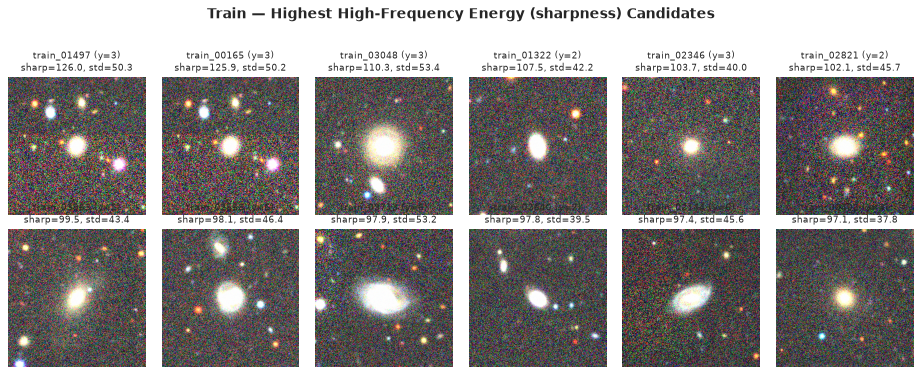

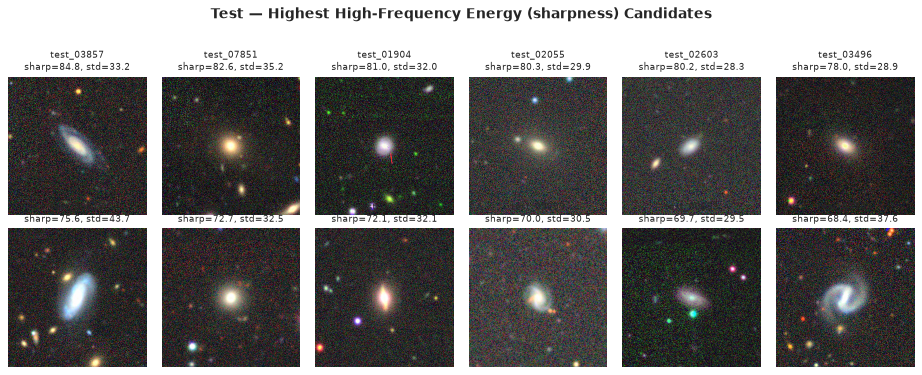

In [8]:
# 6.2 Extreme Noise / High-Frequency Energy Candidates
noisy_train = train_stats.nlargest(12, "sharpness")
noisy_test = test_stats.nlargest(12, "sharpness")

print("Highest sharpness (Laplacian energy) in Train:")
display(noisy_train[["id", "label", "file_size", "mean_gray", "std_gray", "sharpness", "frac_zero", "frac_255"]])

print("Highest sharpness (Laplacian energy) in Test:")
display(noisy_test[["id", "file_size", "mean_gray", "std_gray", "sharpness", "frac_zero", "frac_255"]])

fig = plot_image_grid(
    [TRAIN_DIR / f"{i}.png" for i in noisy_train["id"]],
    titles=[f"{r.id} (y={r.label})\nsharp={r.sharpness:.1f}, std={r.std_gray:.1f}" for r in noisy_train.itertuples()],
    ncols=6,
    suptitle="Train — Highest High-Frequency Energy (sharpness) Candidates",
)
plt.show()

fig = plot_image_grid(
    [TEST_DIR / f"{i}.png" for i in noisy_test["id"]],
    titles=[f"{r.id}\nsharp={r.sharpness:.1f}, std={r.std_gray:.1f}" for r in noisy_test.itertuples()],
    ncols=6,
    suptitle="Test — Highest High-Frequency Energy (sharpness) Candidates",
)
plt.show()

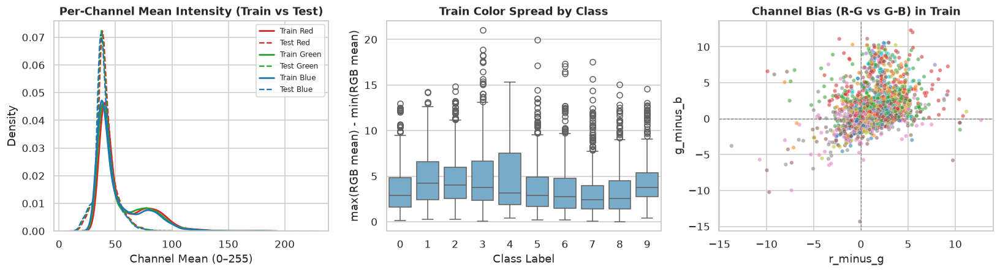

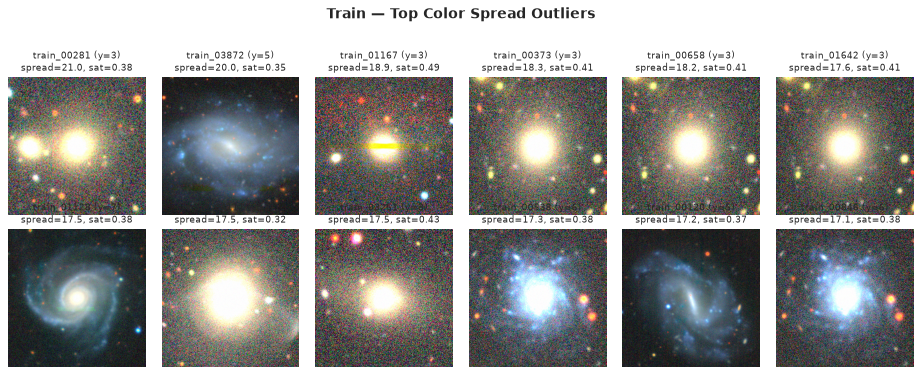

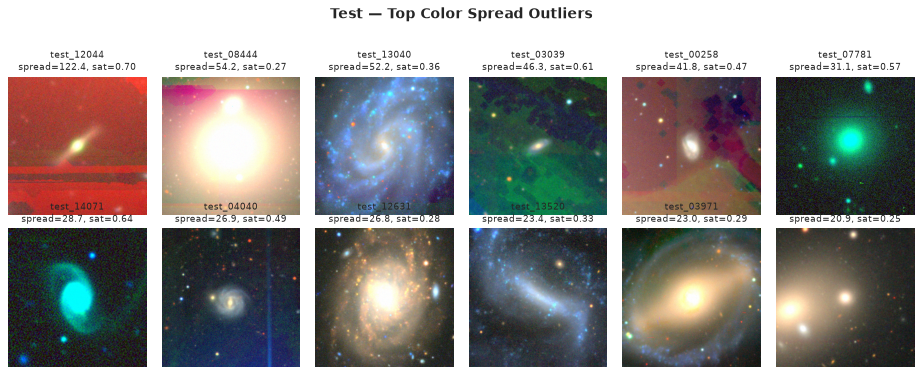

In [9]:
# 6.3 Color Distortion Analysis
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=110)

for ch, color, label in [("mean_r", "tab:red", "Red"), ("mean_g", "tab:green", "Green"), ("mean_b", "tab:blue", "Blue")]:
    sns.kdeplot(train_stats[ch], color=color, label=f"Train {label}", ax=axes[0], linewidth=1.8)
    sns.kdeplot(test_stats[ch], color=color, linestyle="--", label=f"Test {label}", ax=axes[0], linewidth=1.5)
axes[0].set_title("Per-Channel Mean Intensity (Train vs Test)", fontweight="bold")
axes[0].set_xlabel("Channel Mean (0–255)")
axes[0].legend(fontsize=8)

sns.boxplot(data=train_stats, x="label", y="color_spread", ax=axes[1], color="#6baed6")
axes[1].set_title("Train Color Spread by Class", fontweight="bold")
axes[1].set_xlabel("Class Label")
axes[1].set_ylabel("max(RGB mean) - min(RGB mean)")

sns.scatterplot(
    data=train_stats.sample(min(2000, len(train_stats)), random_state=SEED),
    x="r_minus_g",
    y="g_minus_b",
    hue="label",
    palette="tab10",
    alpha=0.55,
    s=18,
    ax=axes[2],
    legend=False,
)
axes[2].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[2].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[2].set_title("Channel Bias (R-G vs G-B) in Train", fontweight="bold")

plt.tight_layout()
plt.show()

color_train = train_stats.nlargest(12, "color_spread")
color_test = test_stats.nlargest(12, "color_spread")

fig = plot_image_grid(
    [TRAIN_DIR / f"{i}.png" for i in color_train["id"]],
    titles=[f"{r.id} (y={r.label})\nspread={r.color_spread:.1f}, sat={r.mean_sat:.2f}" for r in color_train.itertuples()],
    ncols=6,
    suptitle="Train — Top Color Spread Outliers",
)
plt.show()

fig = plot_image_grid(
    [TEST_DIR / f"{i}.png" for i in color_test["id"]],
    titles=[f"{r.id}\nspread={r.color_spread:.1f}, sat={r.mean_sat:.2f}" for r in color_test.itertuples()],
    ncols=6,
    suptitle="Test — Top Color Spread Outliers",
)
plt.show()

Exact file_md5 duplicates within train: 0
Exact pixel_md5 duplicates within train: 0
Exact file_md5 duplicates within test:  0
Exact pixel_md5 duplicates within test:  0
Exact file_md5 overlap train <-> test:  0
Exact pixel_md5 overlap train <-> test: 0



dHash near-duplicate pairs (Hamming <= 4):
  Train <-> Train: 2,014 pairs
    Label conflicts among sampled pairs: 1481 / 2014
  Train <-> Test:  5,614 pairs
  Test  <-> Test:  7,020 pairs

Sample Train <-> Train near-duplicate pairs:


,id_a,id_b,split_a,split_b,label_a,label_b,same_pixel_md5,hamming
0,train_00032,train_02471,train,train,3,2,False,0
1,train_00059,train_01109,train,train,3,3,False,0
2,train_00076,train_01106,train,train,3,2,False,0
3,train_00097,train_01745,train,train,5,6,False,0
4,train_00128,train_00927,train,train,3,3,False,0
5,train_00137,train_01075,train,train,3,2,False,0
6,train_00137,train_03922,train,train,3,3,False,0
7,train_00149,train_04104,train,train,5,5,False,0
8,train_00168,train_01150,train,train,2,3,False,0
9,train_00168,train_02950,train,train,2,2,False,0


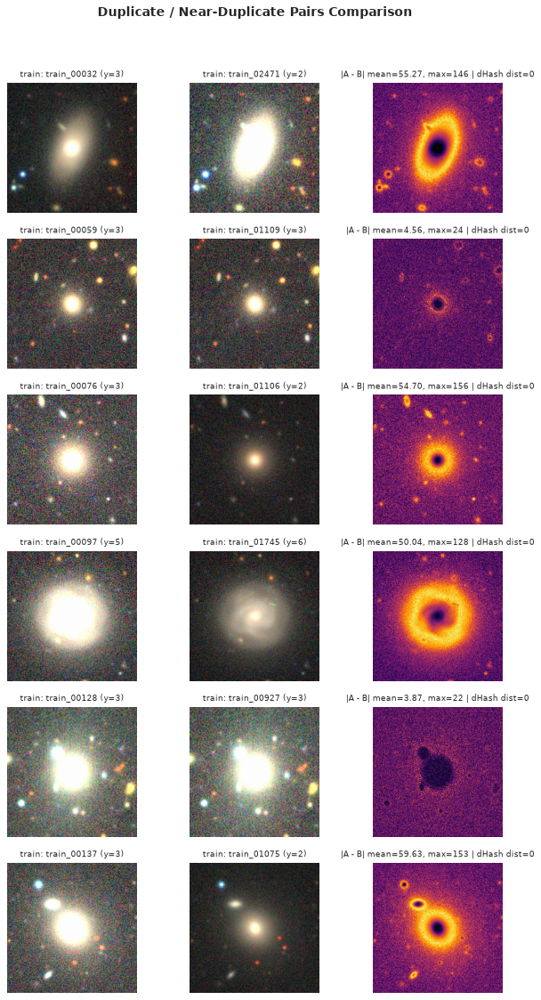


Sample Train <-> Test near-duplicate pairs:


,id_a,id_b,split_a,split_b,label_a,label_b,same_pixel_md5,hamming
0,train_00261,test_01116,train,test,6,NaN,False,0
1,train_00261,test_13329,train,test,6,NaN,False,0
2,train_00647,test_01246,train,test,5,NaN,False,0
3,train_00647,test_10259,train,test,5,NaN,False,0
4,train_01348,test_08095,train,test,5,NaN,False,0
5,train_01672,test_01246,train,test,6,NaN,False,0
6,train_01672,test_10259,train,test,6,NaN,False,0
7,train_01728,test_02693,train,test,6,NaN,False,0
8,train_01728,test_07270,train,test,6,NaN,False,0
9,train_01728,test_08636,train,test,6,NaN,False,0


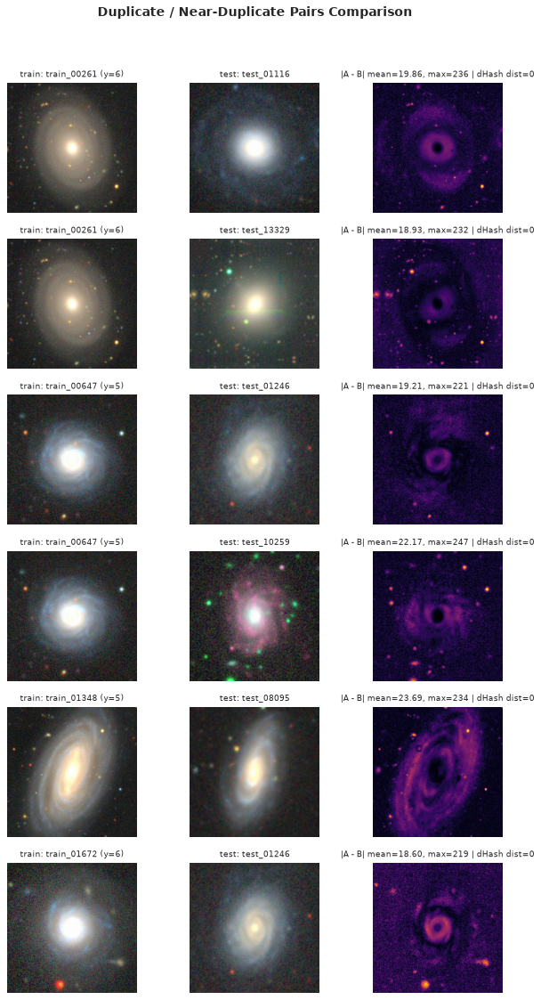

In [10]:
# 6.4 Exact Duplicates & Perceptual Near-Duplicates (dHash Hamming <= 4)
def summarize_exact_duplicates(df_a: pd.DataFrame, df_b: pd.DataFrame | None = None, col: str = "pixel_md5") -> pd.DataFrame:
    if df_b is None:
        dups = df_a[df_a.duplicated(subset=[col], keep=False)].sort_values([col, "id"])
        return dups
    common = set(df_a[col]) & set(df_b[col])
    return pd.concat([df_a[df_a[col].isin(common)], df_b[df_b[col].isin(common)]], ignore_index=True).sort_values([col, "split", "id"])


print("Exact file_md5 duplicates within train:", int(train_stats["file_md5"].duplicated().sum()))
print("Exact pixel_md5 duplicates within train:", int(train_stats["pixel_md5"].duplicated().sum()))
print("Exact file_md5 duplicates within test: ", int(test_stats["file_md5"].duplicated().sum()))
print("Exact pixel_md5 duplicates within test: ", int(test_stats["pixel_md5"].duplicated().sum()))

cross_file_dups = set(train_stats["file_md5"]) & set(test_stats["file_md5"])
cross_pixel_dups = set(train_stats["pixel_md5"]) & set(test_stats["pixel_md5"])
print("Exact file_md5 overlap train <-> test: ", len(cross_file_dups))
print("Exact pixel_md5 overlap train <-> test:", len(cross_pixel_dups))


def find_near_duplicates(
    df_a: pd.DataFrame,
    bits_a: np.ndarray,
    df_b: pd.DataFrame | None = None,
    bits_b: np.ndarray | None = None,
    max_hamming: int = 4,
    chunk_size: int = 1024,
    max_keep: int = 25000,
) -> tuple[int, pd.DataFrame]:
    """Find pairs within Hamming distance <= max_hamming using chunked bit-matrix multiplication."""
    within = df_b is None
    if within:
        df_b, bits_b = df_a, bits_a

    A = bits_a.astype(np.float32)
    B = bits_b.astype(np.float32)
    sum_a = A.sum(axis=1)
    sum_b = B.sum(axis=1)

    total_pairs = 0
    rows = []

    for i0 in range(0, len(A), chunk_size):
        i1 = min(i0 + chunk_size, len(A))
        j_start = i0 if within else 0
        for j0 in range(j_start, len(B), chunk_size):
            j1 = min(j0 + chunk_size, len(B))
            dists = sum_a[i0:i1, None] + sum_b[None, j0:j1] - 2.0 * (A[i0:i1] @ B[j0:j1].T)
            mask = dists <= max_hamming + 1e-4
            if within and i0 == j0:
                mask &= np.triu(np.ones_like(mask, dtype=bool), k=1)

            ii, jj = np.where(mask)
            total_pairs += len(ii)
            if len(rows) < max_keep and len(ii) > 0:
                take = min(len(ii), max_keep - len(rows))
                for r_idx, c_idx in zip(ii[:take], jj[:take], strict=True):
                    ra = df_a.iloc[i0 + int(r_idx)]
                    rb = df_b.iloc[j0 + int(c_idx)]
                    rows.append({
                        "id_a": ra["id"],
                        "id_b": rb["id"],
                        "split_a": ra["split"],
                        "split_b": rb["split"],
                        "label_a": ra.get("label", np.nan),
                        "label_b": rb.get("label", np.nan),
                        "same_pixel_md5": ra["pixel_md5"] == rb["pixel_md5"],
                        "hamming": int(round(float(dists[r_idx, c_idx]))),
                    })

    pairs_df = pd.DataFrame(rows)
    if not pairs_df.empty:
        pairs_df = pairs_df.sort_values(["hamming", "id_a", "id_b"]).reset_index(drop=True)
    return total_pairs, pairs_df


n_tr_tr, pairs_tr_tr = find_near_duplicates(train_stats, train_scan["dhash"], max_hamming=4)
n_tr_te, pairs_tr_te = find_near_duplicates(train_stats, train_scan["dhash"], test_stats, test_scan["dhash"], max_hamming=4)
n_te_te, pairs_te_te = find_near_duplicates(test_stats, test_scan["dhash"], max_hamming=4)

print(f"\ndHash near-duplicate pairs (Hamming <= 4):")
print(f"  Train <-> Train: {n_tr_tr:,} pairs")
if not pairs_tr_tr.empty:
    conflicts = int((pairs_tr_tr["label_a"] != pairs_tr_tr["label_b"]).sum())
    print(f"    Label conflicts among sampled pairs: {conflicts} / {len(pairs_tr_tr)}")
print(f"  Train <-> Test:  {n_tr_te:,} pairs")
print(f"  Test  <-> Test:  {n_te_te:,} pairs")

if not pairs_tr_tr.empty:
    print("\nSample Train <-> Train near-duplicate pairs:")
    display(pairs_tr_tr.head(10))
    fig = plot_duplicate_pairs(pairs_tr_tr, TRAIN_DIR, TEST_DIR, max_pairs=6)
    plt.show()

if not pairs_tr_te.empty:
    print("\nSample Train <-> Test near-duplicate pairs:")
    display(pairs_tr_te.head(10))
    fig = plot_duplicate_pairs(pairs_tr_te, TRAIN_DIR, TEST_DIR, max_pairs=6)
    plt.show()

Train spatial stats — mean range: [40.77, 240.86] | std range: [24.88, 68.97] | zero-std pixels: 0
Test spatial stats  — mean range: [32.99, 217.73] | std range: [17.01, 56.75] | zero-std pixels: 0


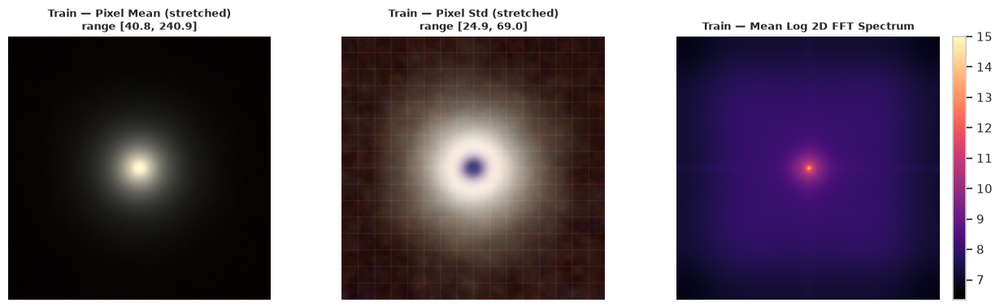

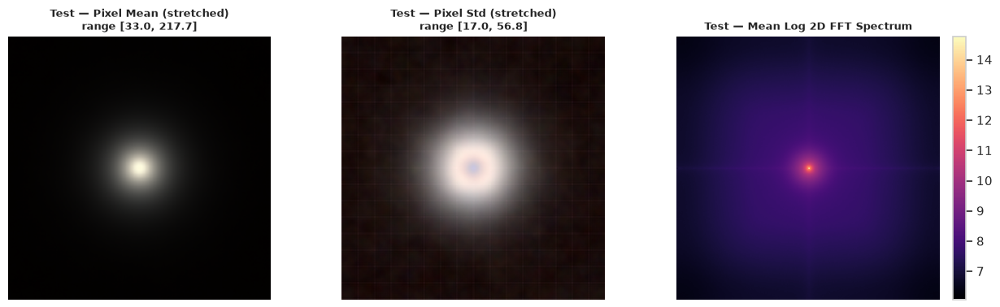

In [11]:
# 6.5 Systematic Spatial & Frequency-Domain Disturbances
print(
    "Train spatial stats — mean range:",
    f"[{train_scan['mean_img'].min():.2f}, {train_scan['mean_img'].max():.2f}]",
    "| std range:",
    f"[{train_scan['std_img'].min():.2f}, {train_scan['std_img'].max():.2f}]",
    "| zero-std pixels:",
    int((train_scan["std_img"] < 1e-6).sum()),
)
print(
    "Test spatial stats  — mean range:",
    f"[{test_scan['mean_img'].min():.2f}, {test_scan['mean_img'].max():.2f}]",
    "| std range:",
    f"[{test_scan['std_img'].min():.2f}, {test_scan['std_img'].max():.2f}]",
    "| zero-std pixels:",
    int((test_scan["std_img"] < 1e-6).sum()),
)

fig = plot_spatial_maps(train_scan["mean_img"], train_scan["std_img"], train_scan["fft_mag"], title_prefix="Train")
plt.show()

fig = plot_spatial_maps(test_scan["mean_img"], test_scan["std_img"], test_scan["fft_mag"], title_prefix="Test")
plt.show()

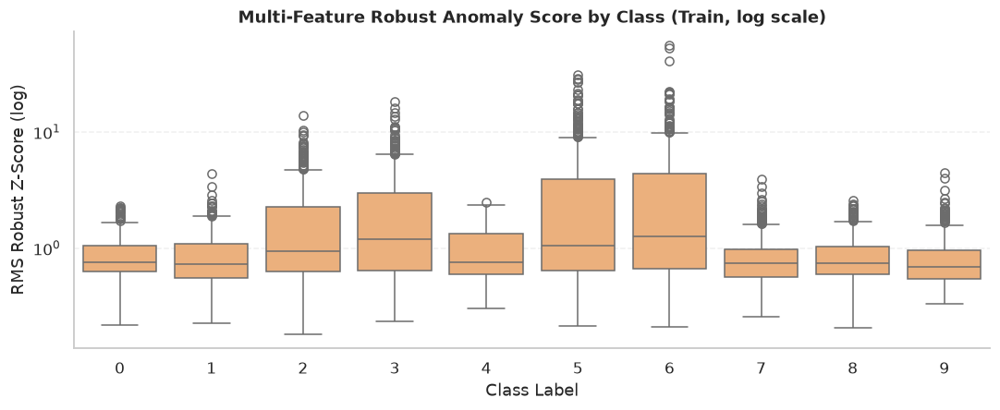

Top 10 Train Anomalies:


,id,label,anomaly_score,file_size,mean_gray,std_gray,color_spread,sharpness,frac_zero,frac_255
1861,train_01861,6,55.332480,138053,180.715698,74.059219,4.516769,19.321028,0.000000,0.390656
1368,train_01368,6,52.955671,137817,177.185211,75.228203,4.663788,18.858009,0.000000,0.373871
851,train_00851,6,40.546251,135624,158.220428,78.851822,7.415329,16.540831,0.000000,0.286118
3399,train_03399,5,30.946482,172551,169.268433,60.517300,2.693680,67.711464,0.000015,0.218048
2929,train_02929,5,28.570766,162020,134.629486,70.210854,0.937897,42.171741,0.000000,0.202179
2156,train_02156,5,28.254904,165615,148.825348,69.738983,9.037674,37.410942,0.000000,0.199432
142,train_00142,5,26.740043,163724,141.326340,69.240570,4.136307,35.506550,0.000000,0.188843
2999,train_02999,5,26.733391,170898,142.565140,69.146049,8.857178,60.588654,0.000000,0.188782
1894,train_01894,5,23.096924,171381,126.239983,70.124352,1.255951,63.787277,0.000000,0.163406
1913,train_01913,6,22.314965,174469,137.271912,70.820435,1.660095,70.299721,0.000000,0.157440


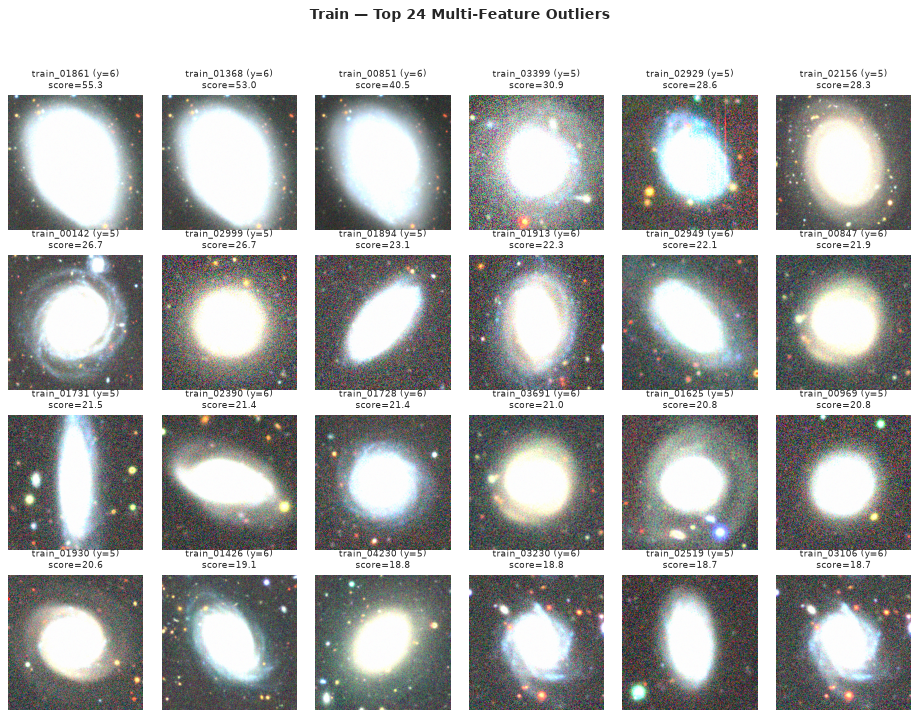

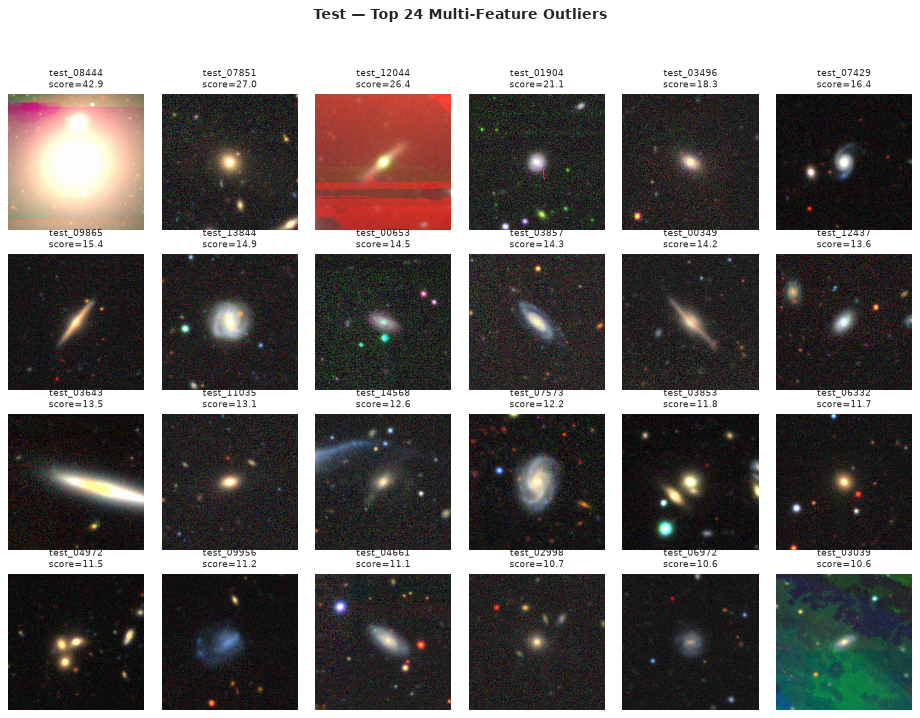

In [12]:
# 6.6 Multi-Feature Robust Outlier Score ("Area 51" Gallery)
OOD_FEATURES = [
    "file_size",
    "mean_gray",
    "std_gray",
    "color_spread",
    "r_minus_g",
    "r_minus_b",
    "mean_sat",
    "frac_zero",
    "frac_255",
    "center_border_diff",
    "sharpness",
]

# Fit median and MAD strictly on training set so train and test share the same scale
medians = train_stats[OOD_FEATURES].median()
mads = (train_stats[OOD_FEATURES] - medians).abs().median()
scales = (1.4826 * mads).clip(lower=1e-4)

z_train = (train_stats[OOD_FEATURES] - medians) / scales
z_test = (test_stats[OOD_FEATURES] - medians) / scales

train_stats["anomaly_score"] = np.sqrt(np.square(z_train).mean(axis=1))
test_stats["anomaly_score"] = np.sqrt(np.square(z_test).mean(axis=1))

fig, ax = plt.subplots(figsize=(10, 4.2), dpi=110)
sns.boxplot(data=train_stats, x="label", y="anomaly_score", ax=ax, color="#fdae6b", showfliers=True)
ax.set_yscale("log")
ax.set_title("Multi-Feature Robust Anomaly Score by Class (Train, log scale)", fontweight="bold")
ax.set_xlabel("Class Label")
ax.set_ylabel("RMS Robust Z-Score (log)")
ax.grid(axis="y", alpha=0.3, linestyle="--")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

top_ood_train = train_stats.nlargest(24, "anomaly_score")
top_ood_test = test_stats.nlargest(24, "anomaly_score")

print("Top 10 Train Anomalies:")
display(top_ood_train[["id", "label", "anomaly_score", "file_size", "mean_gray", "std_gray", "color_spread", "sharpness", "frac_zero", "frac_255"]].head(10))

fig = plot_image_grid(
    [TRAIN_DIR / f"{i}.png" for i in top_ood_train["id"]],
    titles=[f"{r.id} (y={r.label})\nscore={r.anomaly_score:.1f}" for r in top_ood_train.itertuples()],
    ncols=6,
    suptitle="Train — Top 24 Multi-Feature Outliers",
)
plt.show()

fig = plot_image_grid(
    [TEST_DIR / f"{i}.png" for i in top_ood_test["id"]],
    titles=[f"{r.id}\nscore={r.anomaly_score:.1f}" for r in top_ood_test.itertuples()],
    ncols=6,
    suptitle="Test — Top 24 Multi-Feature Outliers",
)
plt.show()

## 7. Train vs. Test Distribution Shift

Compare key image-level feature distributions between `train` and `test` to identify domain shift, differing corruption rates, or unseen imaging regimes.

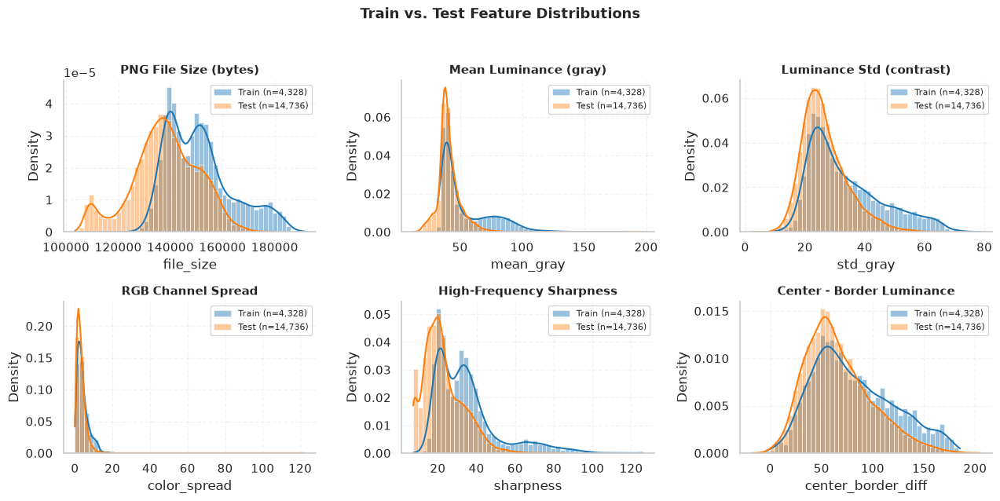

,metric,train_median,test_median,train_p99,test_above_train_p99_pct,train_p01,test_below_train_p01_pct
0,anomaly_score,0.8400,0.9814,14.5010,0.0611,0.3074,0.1425
1,std_gray,29.9672,25.1857,65.5415,0.0068,16.6136,5.1846
2,color_spread,3.3132,2.7145,13.1399,0.5836,0.3192,1.3912
3,sharpness,31.4720,20.8152,89.1380,0.0000,16.2964,28.4541
4,frac_zero,0.0000,0.0000,0.0002,7.6412,0.0000,0.0000
5,frac_255,0.0020,0.0011,0.1020,0.0068,0.0000,0.0000


In [13]:
compare_cols = [
    "file_size",
    "mean_gray",
    "std_gray",
    "color_spread",
    "sharpness",
    "center_border_diff",
]
fig = plot_distribution_comparison(
    train_stats,
    test_stats,
    columns=compare_cols,
    titles=[
        "PNG File Size (bytes)",
        "Mean Luminance (gray)",
        "Luminance Std (contrast)",
        "RGB Channel Spread",
        "High-Frequency Sharpness",
        "Center - Border Luminance",
    ],
    ncols=3,
)
plt.show()

# Compare outlier prevalence using train 99th-percentile thresholds
shift_rows = []
for col in ["anomaly_score", "std_gray", "color_spread", "sharpness", "frac_zero", "frac_255"]:
    p01 = float(train_stats[col].quantile(0.01))
    p99 = float(train_stats[col].quantile(0.99))
    shift_rows.append({
        "metric": col,
        "train_median": float(train_stats[col].median()),
        "test_median": float(test_stats[col].median()),
        "train_p99": p99,
        "test_above_train_p99_pct": float((test_stats[col] > p99).mean() * 100.0),
        "train_p01": p01,
        "test_below_train_p01_pct": float((test_stats[col] < p01).mean() * 100.0),
    })

display(pd.DataFrame(shift_rows).round(4))

## 8. Key Takeaways & Next Steps

Run the summary cell below to consolidate quantitative findings from this exploration.

In [14]:
ood_p99 = float(train_stats["anomaly_score"].quantile(0.99))
summary_lines = [
    f"Train samples: {len(train_stats):,} | Test samples: {len(test_stats):,} (ratio {len(test_stats)/len(train_stats):.2f}x)",
    f"Classes: {train_stats['label'].nunique()} (0..9) | Counts min={class_counts.min()} (class {class_counts.idxmin()}), max={class_counts.max()} (class {class_counts.idxmax()}), imbalance={imbalance_ratio:.2f}x",
    f"Corrupt PNGs: train={int(train_stats['corrupt'].sum())}, test={int(test_stats['corrupt'].sum())}",
    f"Exact pixel duplicates: within_train={int(train_stats['pixel_md5'].duplicated().sum())}, within_test={int(test_stats['pixel_md5'].duplicated().sum())}, train<->test={len(cross_pixel_dups)}",
    f"Perceptual near-duplicates (dHash <= 4): train<->train={n_tr_tr:,}, train<->test={n_tr_te:,}, test<->test={n_te_te:,}",
    f"Images exceeding train 99th-pct anomaly score ({ood_p99:.2f}): train={(train_stats['anomaly_score'] > ood_p99).mean()*100:.2f}%, test={(test_stats['anomaly_score'] > ood_p99).mean()*100:.2f}%",
]
print("\n".join(f"- {line}" for line in summary_lines))

- Train samples: 4,328 | Test samples: 14,736 (ratio 3.40x)
- Classes: 10 (0..9) | Counts min=83 (class 4), max=744 (class 2), imbalance=8.96x
- Corrupt PNGs: train=0, test=0
- Exact pixel duplicates: within_train=0, within_test=0, train<->test=0
- Perceptual near-duplicates (dHash <= 4): train<->train=2,014, train<->test=5,614, test<->test=7,020
- Images exceeding train 99th-pct anomaly score (14.50): train=1.02%, test=0.06%


### Key Findings & Next Steps
1. **Scale & Class Imbalance:** `4,328` training vs. `14,736` test images (`3.40x` larger test set), all `256 × 256` RGB PNGs with zero corrupt headers or missing IDs. Class counts range from `83` (`class 4`, `1.92%`) to `744` (`class 2`, `17.19%`) — an `8.96x` imbalance ratio that directly affects **weighted F1-score**.
2. **Blank / Starless Observations:** `train_03848` (`label=8`, `std_gray=2.01`, `max_val=46`) and test frames `test_13385` / `test_13646` (`std_gray=2.01`, `max_val=46`) contain pure low-variance background noise with no visible stars.
3. **Train vs. Test Shift & Unseen Corruptions:** `test` images exhibit markedly lower median high-frequency `sharpness` (`20.8` vs. `31.5` in train, with `28.45%` of test below the train 1st percentile) alongside extreme color/stripe/patch artifacts not present at the same severity in train (e.g., `test_12044` with `color_spread=122.4` vs. train max `21.0`).
4. **Near-Duplicates & Label Consistency (`dHash <= 4`):** `9×8` `dHash` surfaces `2,014` train↔train pairs (which mix centered-galaxy collisions with genuine same-star-field duplicates that have conflicting labels, such as `train_00032` vs. `train_02471`) and `5,614` train↔test pairs.
5. **Recommended Next Actions:**
   - **Cleaning (`data/cleaning.py`):** Flag blank/starless frames, separate genuine same-field near-duplicates from centered-galaxy `dHash` collisions using higher-resolution perceptual similarity / pixel correlation, and inspect conflicting-label duplicates.
   - **Validation (`eval/`):** Use `StratifiedKFold` (or `StratifiedGroupKFold` over true duplicate clusters) optimizing **weighted F1-score**.
   - **Augmentation & Modeling (`data/preprocessing.py`, `model/`):** Use color-jitter / stripe / channel-shift / noise-robust augmentations and test-time robustness to handle the severe test-set color distortions and sharpness shift.